# Settings

In [1]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/001_params_angles_ref2.json"

run_beamforming = True
show_object_images = True

#saved names
save_image = True

#for rf data
rf_data_path = "./data_rf/"
folder_name = "master_thesis" 
rf_data_name = "001_rf_results_angles_ref2"

# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from numba.experimental import jitclass
from numba import float64, float32
import json
import os

# Import parameters

In [3]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [4]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [5]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.0072 m


# Create workspace 

In [6]:

saving_path = f"{rf_data_path}{folder_name}/"

if not os.path.exists(saving_path):
    os.makedirs(saving_path)
    print(f"Created directory {saving_path}")
os.makedirs(f"{saving_path}images/", exist_ok=True)
os.makedirs(f"{saving_path}rf/", exist_ok=True)
os.makedirs(f"{saving_path}beamformed/", exist_ok=True)

## Objects

In [7]:
spec = [
    ('depth', float64), #depth of the object
    ('position', float64), #position of the object
    ('delays', float64[:,:]), #delays for each element of the array
    ('rf_matrix', float64[:,:,:]), #RF matrix (samples, array length, angles)
    ('rf_matrix_upsampled', float64[:,:,:]), #upsampled RF matrix (samples, array length, angles)
    ('effective_array_length', float64), #effective array length
    ('effective_angle', float64) #effective angle
]

@jitclass(spec)
class Objects:
    def __init__(self, depth, position, array_length, samples, upsampled_samples, angles_len):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(shape = (array_length, angles_len), dtype=np.float64)
        self.rf_matrix = np.zeros(shape = (samples, array_length, angles_len), dtype=np.float64)
        self.rf_matrix_upsampled = np.zeros(shape = (upsampled_samples, array_length, angles_len), dtype=np.float64)
        self.effective_array_length = 0
        self.effective_angle = 0

# Signals

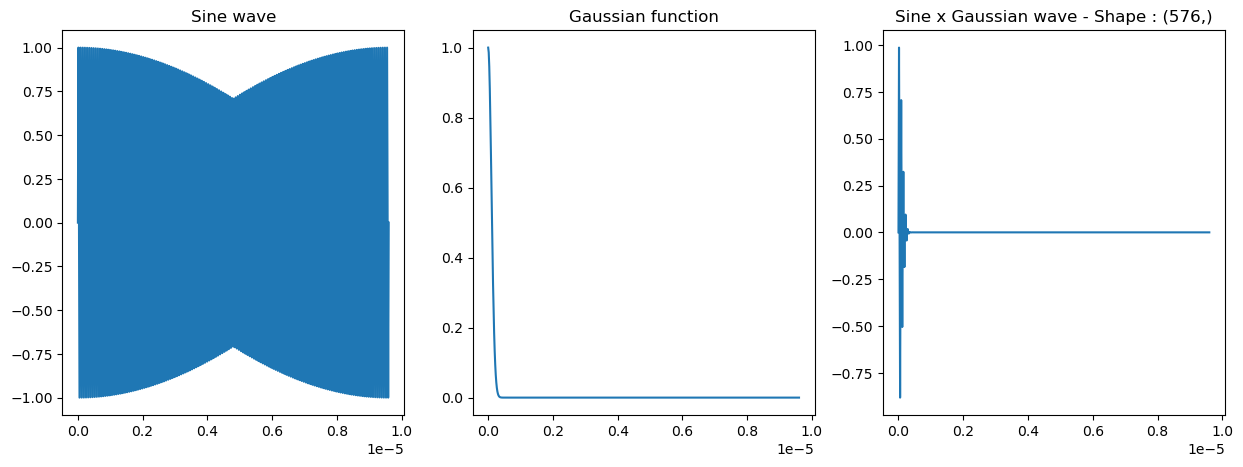

In [8]:
gaussian_std = 0.0000001

@njit()
def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep)

@njit()
def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

@njit()
def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

fig, ax = plt.subplots(1,3, figsize=(15,5))

wave1, wave2, wave3 = sine_wave(params['rf']['frequency'], time), gaussian_function(time, gaussian_std), generate_wave(params['rf']['frequency'], time, gaussian_std)
ax[0].plot(time, wave1)
ax[0].set_title("Sine wave")

ax[1].plot(time, wave2)
ax[1].set_title("Gaussian function")

ax[2].plot(time, wave3)
ax[2].set_title(f"Sine x Gaussian wave - Shape : {wave3.shape}")
plt.show()

# Delays

In [9]:
@njit()
def delay_function(object_depth, object_position, speed_sound, array_position, pitch, angle):
    return ((object_depth * np.cos(angle * np.pi/180) + object_position * np.sin(angle * np.pi/180)) / speed_sound)  + (np.sqrt(object_depth**2 + (array_position * pitch - object_position)**2) / speed_sound)

In [10]:
@njit()
def get_delays(objects, c, pitch, array_length, angles, delay0, sampling_rate):
    initial_delay = delay0 * 1 / sampling_rate
    for i in range(0, len(angles)):
        for j in range(0, len(objects)):
            for k in range(0, array_length):
                 objects[j].delays[k, i] = delay_function(object_depth=objects[j].depth, object_position=objects[j].position, speed_sound=c, array_position=k, pitch=pitch, angle=angles[i]) - initial_delay

## Find object effective aperture 

In [11]:
@njit()
def find_object_effective_aperture(objects, aperture):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture

## Wave delays

In [12]:
@njit()	
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch <= current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch >= current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return np.cos(np.abs(current_object.position - current_transducer * pitch) / current_object.effective_array_length) ** 2

In [13]:
@njit(parallel=True)
def get_rf_matrices(objects : Objects, frequency, time, array_length, pitch, gaussian_std, samples, angles = [0]):
    rf_matrices_summed = np.zeros((samples, array_length, len(angles)))

    for i in range(0, len(angles)):
        for j in range(0, len(objects)):
            for k in range(array_length):
                #for each transducer, generate the wave with the corresponding delay
                objects[j].rf_matrix[:,k,i] += generate_wave(frequency, time - objects[j].delays[k,i], gaussian_std) * is_in_transducer_range(objects[j], k, pitch)
            
            rf_matrices_summed[:,:,i] += objects[j].rf_matrix[:,:,i] 
    
    return rf_matrices_summed

## Showing wave results

In [14]:
def plot_rf_matrices_heatmaps(rf_matrices_summed, angles = [0]):
    n_matrices = rf_matrices_summed.shape[2]
    n_cols = min(3, n_matrices)
    n_rows = (n_matrices + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*4))
    
    if n_matrices > 1 and n_rows > 1:
        axes = axes.flatten()
    elif n_matrices > 1:
        #if single row but multiple columns
        axes = axes
    else:
        #if just one plot - otherwise obj is not subscriptable
        axes = [axes]
    
    for i in range(n_matrices):
        if i < len(axes):
            im = axes[i].imshow(rf_matrices_summed[:,:,i], aspect='auto', cmap='viridis')
            axes[i].set_title(f'RF Matrix at Angle {angles[i]}°')
            axes[i].set_xlabel('Transducer idx')
            axes[i].set_ylabel('Sample idx')
            fig.colorbar(im, ax=axes[i], label='Amplitude')

    for i in range(n_matrices, len(axes)):
        fig.delaxes(axes[i]) #remove empty plots
    
    plt.tight_layout()
    if save_image:
        plt.savefig(f"{rf_data_path}{folder_name}/images/rf_matrices.png")
    plt.show()

# Beamforming

In [15]:
def save_beamformed_data(bf_matrix, filename, destination="./data_rf/latest/beamformed/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data saved at: {destination}{filename}.npy")

In [16]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices_arg, nx, nz, dx, dz, x0, z0, delay0, pitch, c, array_length, samples, sampling_rate, angles_arg = [0]):
    print(rf_summed_matrices_arg.shape)
    max_acquisition_depth = c * (1 / sampling_rate * samples) / 2
    samples_for_acquisition_depth = int(max_acquisition_depth / dz)
    samples_for_array_length = int(array_length * pitch / dx)

    delay0 = delay0 * 1 / sampling_rate


    if nx is None:
        nx = samples_for_array_length
    if nz is None:
        nz = samples_for_acquisition_depth

    bf_matrices = np.zeros((nx, nz, len(angles_arg)))

    scaled_dx = (
        array_length * pitch
    ) / nx  #! works for data with x0 = 0 otherwise we need to calculate the actual
    scaled_dz = (
        samples / sampling_rate * c / 2
    ) / nz  #! dstance to image xmax - xmin

    for i in range(0, len(angles_arg)): #for each angle
        print("processing angle:",angles_arg[i])

        cos_angle = np.cos(angles_arg[i] * np.pi/180)
        sin_angle = np.sin(angles_arg[i] * np.pi/180)

        for j in range(0, nx): #for each lateral res sample

            if j < x0 or j > x0 + nx:
                continue

            for k in range(0, nz): #for vertical res sample

                if k < z0 or k > z0 + nz:
                    continue

                depth = scaled_dz*k
                position = scaled_dx*j
                # we normalize the index to the total array length

                for l in range(0, array_length): #for each transducer

                    delay = ((depth * cos_angle + position * sin_angle) + (np.sqrt(depth**2 + (l * pitch - position)**2))) / c - delay0 #delay in s
                    delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)
                    
                    if delay_idx < samples:
                        bf_matrices[k,j,i] += rf_summed_matrices_arg[delay_idx, l, i] #we take sample in calculated rf_matrix (faster than recalculating)


        print(f"Beamforming done for angle",angles_arg[i],'°')
    return bf_matrices

# Run Workflow

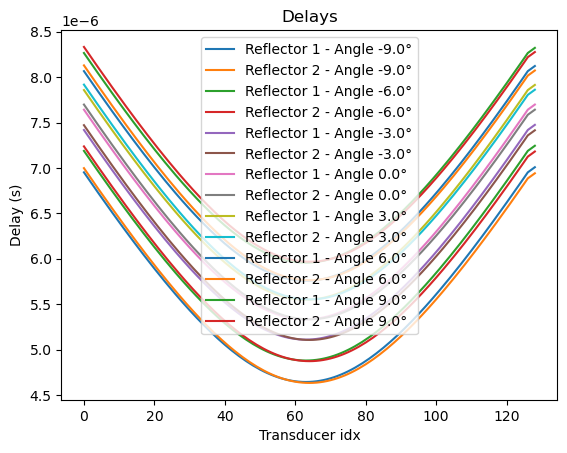

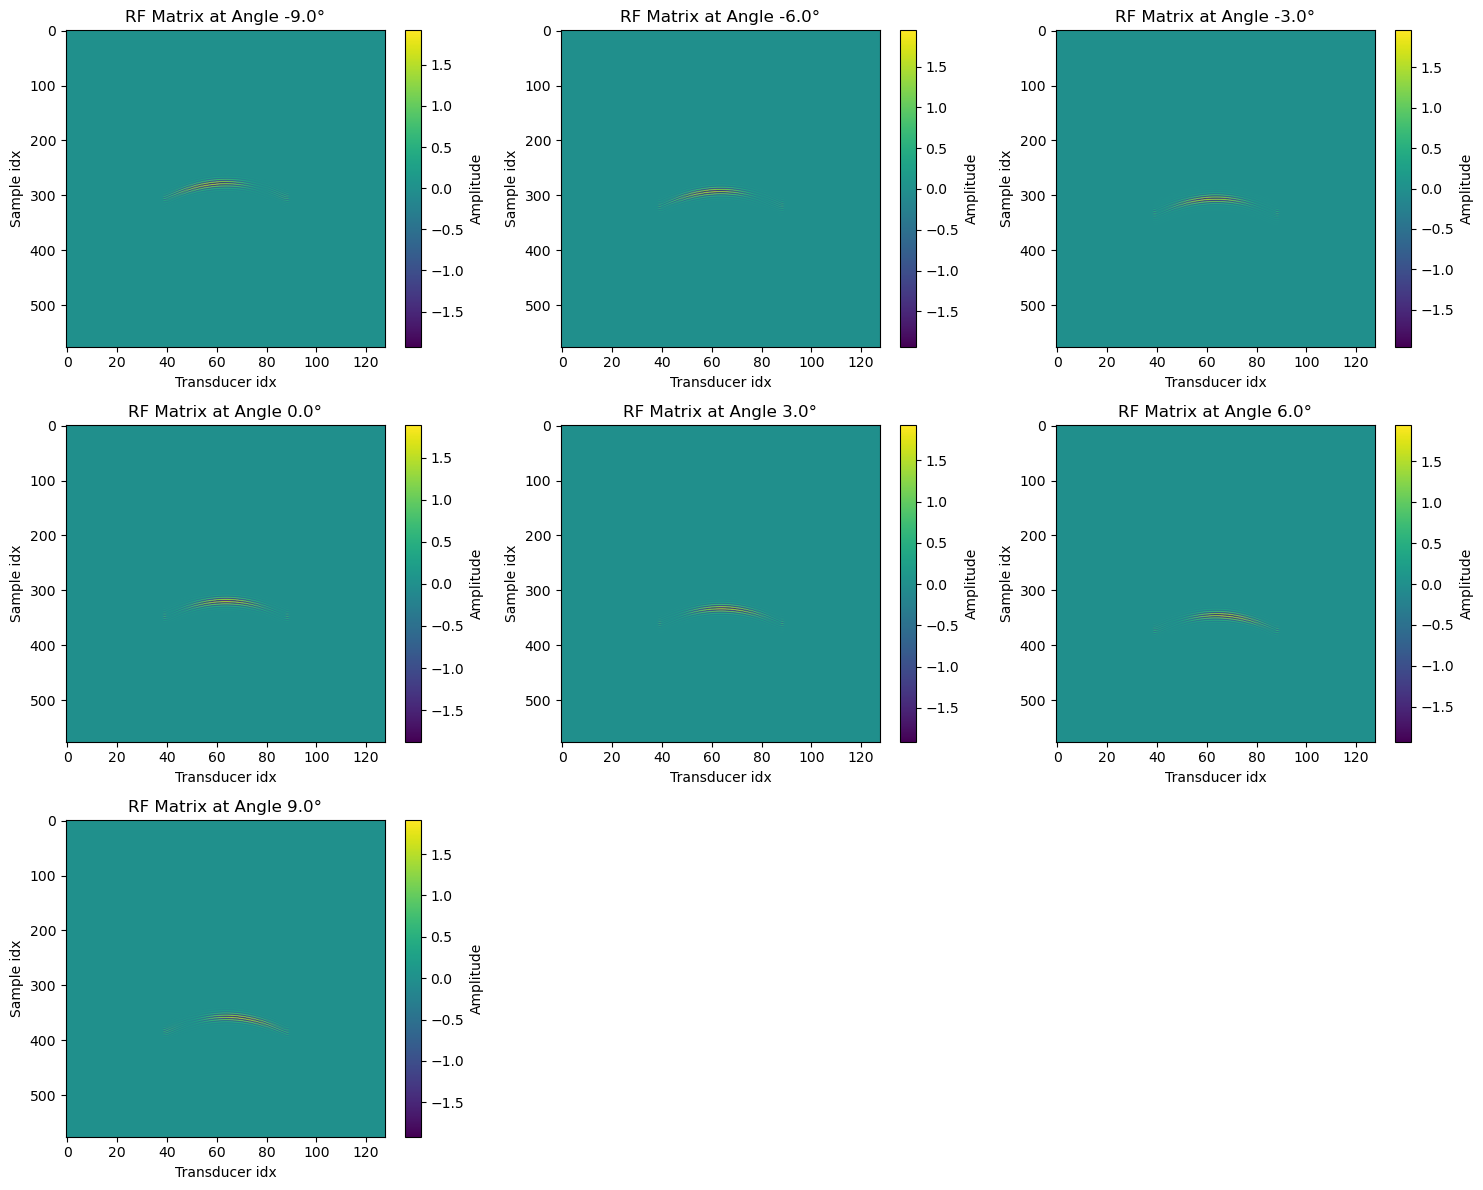

In [17]:
frames = params["image"]["nframes"]

rf_matrices_all_frames = np.zeros((params["rf"]["samples"], params["array"]["length"], len(params["rf"]["angles"]), frames))

for frame in range(frames):
    objects = []

    for reflector in params["objects"][frame]:
        objects.append(
            Objects(
                reflector["depth"], 
                reflector["position"], 
                params["array"]["length"], 
                params["rf"]["samples"], 
                params["rf"]["upsampled_samples"],
                len(params["rf"]["angles"])
                )    
            )
        
    get_delays(objects, C, params["array"]["pitch"], params["array"]["length"], params["rf"]["angles"], params["rf"]["delay0"], params["rf"]["sampling_rate"])

    #visualize delays for each object and angle
    if show_object_images:  
        plt.figure()    
        for i in range (0, len(params["rf"]["angles"])):
            for j in range(0, len(objects)):
                plt.plot(pos, objects[j].delays[:,i], label = f"Reflector {j+1} - Angle {params["rf"]["angles"][i]}°")
        plt.title("Delays")
        plt.xlabel("Transducer idx")
        plt.ylabel("Delay (s)")
        plt.legend()
        plt.show()

    find_object_effective_aperture(objects, params["array"]["aperture"])

    rf_matrices_all_frames[:,:,:,frame] = get_rf_matrices(objects, 
                                            params["rf"]["frequency"],
                                            time,  
                                            params["array"]["length"],  
                                            params["array"]["pitch"],  
                                            gaussian_std,  
                                            params["rf"]["samples"],  
                                            params["rf"]["angles"]
                                            )

    if show_object_images:
        plot_rf_matrices_heatmaps(rf_matrices_all_frames[:,:,:,frame], params["rf"]["angles"])
    
    del objects

In [18]:
(250 * (1 / params["rf"]["sampling_rate"]) * params["rf"]["C"]) / 2

0.003125

In [19]:
save_path = os.path.join(rf_data_path, folder_name, "rf", f"{rf_data_name}.npy")

np.save(save_path, rf_matrices_all_frames)
print(f"RF matrix of shape {rf_matrices_all_frames.shape} saved at: {save_path}")

RF matrix of shape (576, 128, 7, 1) saved at: ./data_rf/master_thesis/rf/001_rf_results_angles_ref2.npy


In [20]:
if run_beamforming:
    bf_matrices = beamforming_opt(
        rf_matrices_all_frames[:,:,:,0], 
        params["image"]["nx"], 
        params["image"]["nz"],
        params["image"]["dx"],
        params["image"]["dz"],
        params["image"]["x0"],
        params["image"]["z0"],
        params["rf"]["delay0"],
        params["array"]["pitch"], 
        C, 
        params["array"]["length"], 
        params["rf"]["samples"], 
        params["rf"]["sampling_rate"], 
        angles_arg=params["rf"]["angles"]
    )

    save_path = os.path.join(rf_data_path, folder_name, "beamformed/")

    save_beamformed_data(bf_matrices, rf_data_name + "_all_angles", destination=save_path)

    bf_matrix_summed = np.sum(bf_matrices, axis=2)
    
    save_beamformed_data(bf_matrix_summed, rf_data_name, destination=save_path)
    

(576, 128, 7)
processing angle: -9.0
Beamforming done for angle -9.0 °
processing angle: -6.0
Beamforming done for angle -6.0 °
processing angle: -3.0
Beamforming done for angle -3.0 °
processing angle: 0.0
Beamforming done for angle 0.0 °
processing angle: 3.0
Beamforming done for angle 3.0 °
processing angle: 6.0
Beamforming done for angle 6.0 °
processing angle: 9.0
Beamforming done for angle 9.0 °
Beamformed data saved at: ./data_rf/master_thesis/beamformed/001_rf_results_angles_ref2_all_angles.npy
Beamformed data saved at: ./data_rf/master_thesis/beamformed/001_rf_results_angles_ref2.npy


## Visualize beamformed image

Beamformed image saved at: ./data_rf/master_thesis/images/001_rf_results_angles_ref2_beamformed.png


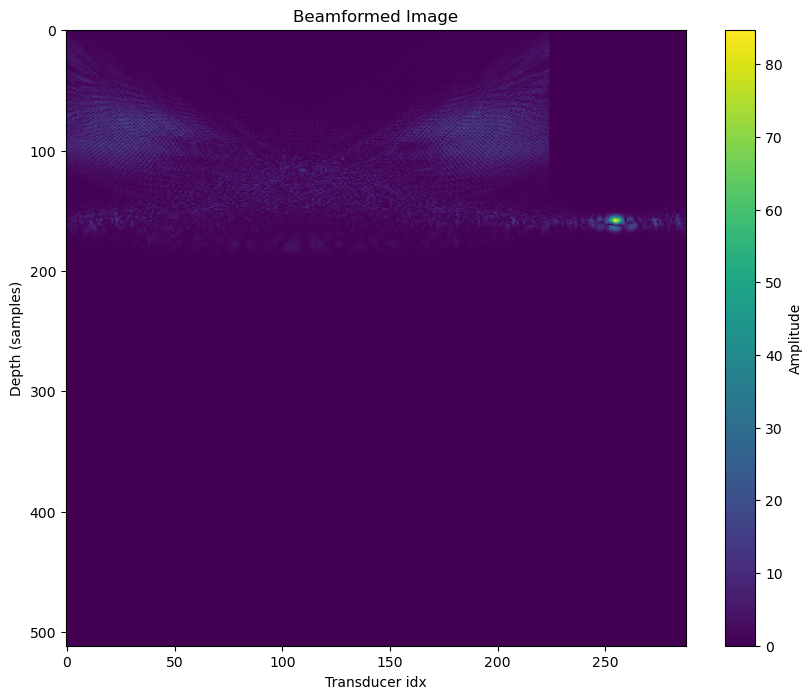

In [21]:
if run_beamforming:
    plt.figure(figsize=(10, 8))
    plt.imshow(np.abs(bf_matrix_summed), cmap='viridis', aspect='auto')
    
    plt.title("Beamformed Image")
    plt.xlabel("Transducer idx")
    plt.ylabel("Depth (samples)")

    # #box around the xo, zo, nx, nz
    # x0 = params["image"]["x0"]
    # z0 = params["image"]["z0"]
    # nx = params["image"]["nx"]
    # nz = params["image"]["nz"]

    # if nx is not None and nz is not None:
    #     plt.plot([x0, x0+nx, x0+nx, x0, x0], [z0, z0, z0+nz, z0+nz, z0], 'r--', label='ROI')
    #     plt.legend()

    plt.colorbar(label="Amplitude")
    if save_image:
        save_path = os.path.join(rf_data_path, folder_name, "images", rf_data_name)

        plt.savefig(save_path + "_beamformed.png")
        print(f"Beamformed image saved at: {save_path}_beamformed.png")
        
    plt.show()